In [2]:
from google.colab import files
uploaded = files.upload()

Saving img2.jpg to img2.jpg


Центроид: (372, 271), Ориентация: -35.93 градусов


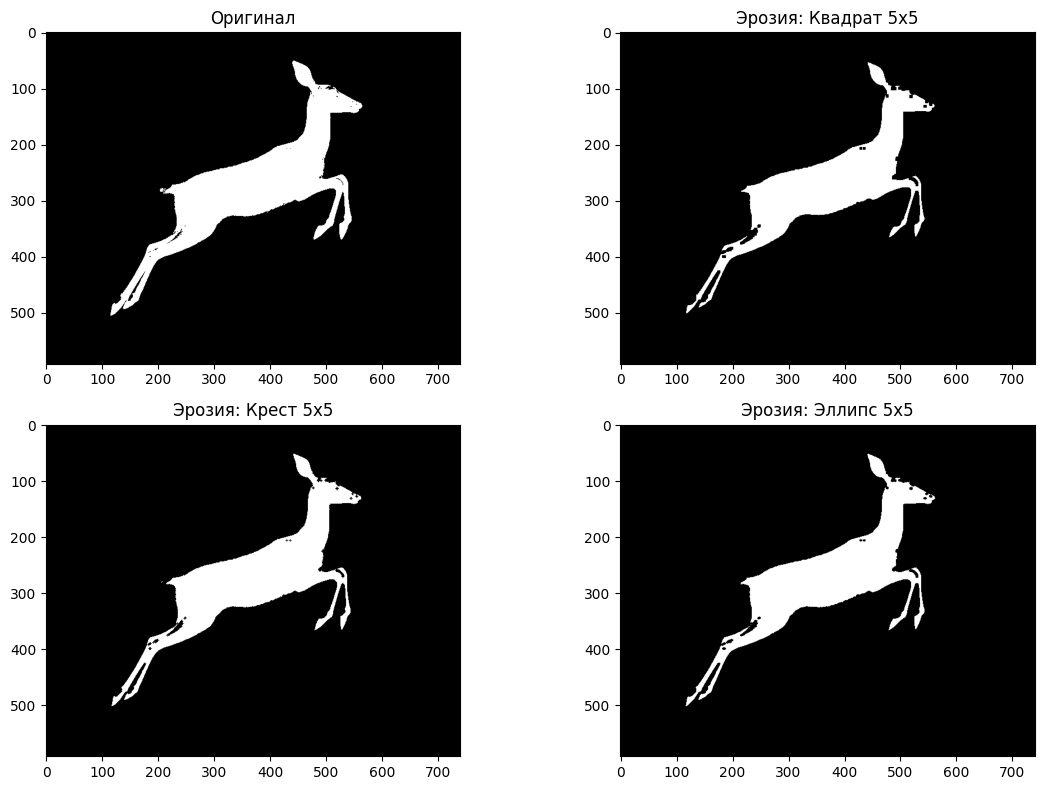

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# загрузка и бинаризация оцу
img_img2 = cv2.imread("img2.jpg")
gray_img2 = cv2.cvtColor(img_img2, cv2.COLOR_BGR2GRAY)
ret, thresh_img2 = cv2.threshold(gray_img2, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# инвертируем
img_inverted = cv2.bitwise_not(thresh_img2)

# поиск контура и вычисление центроида
contours, _ = cv2.findContours(img_inverted, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest_contour = max(contours, key=cv2.contourArea)
M = cv2.moments(largest_contour)

cx = int(M["m10"] / M["m00"])
cy = int(M["m01"] / M["m00"])
orientation_rad = 0.5 * np.arctan2(2 * M["mu11"], (M["mu20"] - M["mu02"]))
orientation_deg = np.degrees(orientation_rad)

print(f"Центроид: ({cx}, {cy}), Ориентация: {orientation_deg:.2f} градусов")

# эрозия с разными ядрами
kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
kernel_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

erode_rect = cv2.erode(img_inverted, kernel_rect, iterations=1)
erode_cross = cv2.erode(img_inverted, kernel_cross, iterations=1)
erode_ellipse = cv2.erode(img_inverted, kernel_ellipse, iterations=1)

# отображение
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_inverted, cmap='gray')
plt.title("Оригинал")

plt.subplot(2, 2, 2)
plt.imshow(erode_rect, cmap='gray')
plt.title("Эрозия: Квадрат 5x5")

plt.subplot(2, 2, 3)
plt.imshow(erode_cross, cmap='gray')
plt.title("Эрозия: Крест 5x5")

plt.subplot(2, 2, 4)
plt.imshow(erode_ellipse, cmap='gray')
plt.title("Эрозия: Эллипс 5x5")

plt.tight_layout()
plt.show()

In [ ]:
'''
При выборе структурного элемента для эрозии важно учитывать форму объекта
если надо аккуратно уменьшить объект и сохранить наклонные линии, то лучше использовать крест'''

In [4]:
from google.colab import files
uploaded = files.upload()

Saving slipped_text.png to slipped_text.png


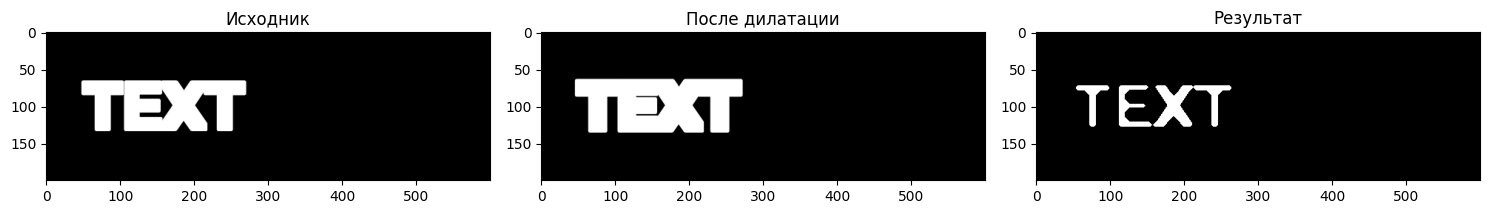

In [5]:
img_to_separate = cv2.imread("slipped_text.png", cv2.IMREAD_GRAYSCALE)

# дилатация
kernel_rect_5 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
img_glued = cv2.dilate(img_to_separate, kernel_rect_5, iterations=1)

# эрозия, threshold,дилатация
kernel_ellipse_3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

# эрозия
img_eroded = cv2.erode(img_to_separate, kernel_ellipse_3, iterations=8)

# убираем серый шум
_, img_clean = cv2.threshold(img_eroded, 254, 255, cv2.THRESH_BINARY)

# утолщаем, дилатация
img_final = cv2.dilate(img_clean, kernel_ellipse_3, iterations=2)

# отображение
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_to_separate, cmap='gray')
plt.title("Исходник")

plt.subplot(1, 3, 2)
plt.imshow(img_glued, cmap='gray')
plt.title("После дилатации")

plt.subplot(1, 3, 3)
plt.imshow(img_final, cmap='gray')
plt.title("Результат")

plt.tight_layout()
plt.show()

In [6]:
from google.colab import files
uploaded = files.upload()

Saving letter_F.png to letter_F.png


In [7]:
img_letter = cv2.imread("letter_F.png", cv2.IMREAD_GRAYSCALE)

skeleton = np.zeros_like(img_letter) # массив нулей, черное изобраежние размерности как наш исходник
img_temp = img_letter.copy()

kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3)) # создаем ядро крест 3х3

In [8]:
# цикл скелетизации
while cv2.countNonZero(img_temp) > 0:
    # применяем открытие, убираем пиксели с краев
    opened = cv2.morphologyEx(img_temp, cv2.MORPH_OPEN, kernel)

    temp = cv2.subtract(img_temp, opened) # находим удаленные края

    skeleton = cv2.bitwise_or(skeleton, temp) # добавляем разницу к скелету

    # уменьшаем букву для след шага эрозией
    img_temp = cv2.erode(img_temp, kernel)


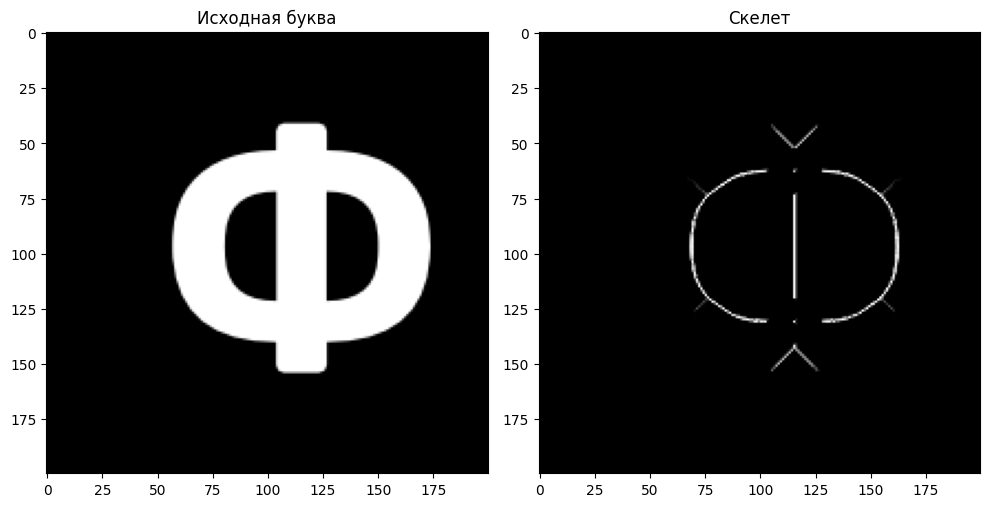

In [9]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_letter, cmap='gray')
plt.title("Исходная буква")

plt.subplot(1, 2, 2)
plt.imshow(skeleton, cmap='gray')
plt.title("Скелет")
plt.tight_layout()
plt.show()

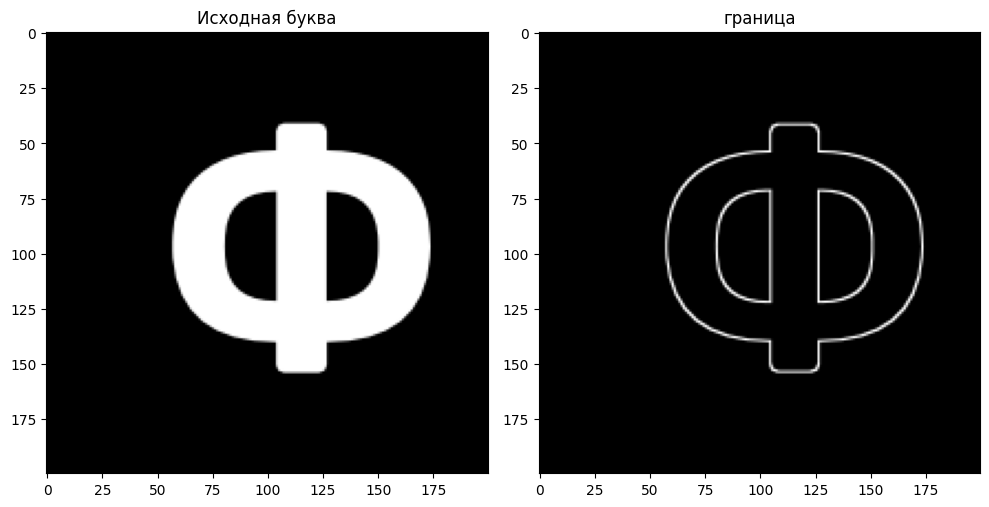

In [10]:
img_letter = cv2.imread("letter_F.png", cv2.IMREAD_GRAYSCALE)

# ядро квадрат 3х3
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# эрозия
eroded = cv2.erode(img_letter, kernel, iterations=1)

# вычитаем эрозию из орига
boundary = cv2.subtract(img_letter, eroded)

# отображение
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_letter, cmap='gray')
plt.title("Исходная буква")

plt.subplot(1, 2, 2)
plt.imshow(boundary, cmap='gray')
plt.title("граница")

plt.tight_layout()
plt.show()

In [11]:
from google.colab import files
uploaded = files.upload()

Saving Шарики.png to Шарики.png


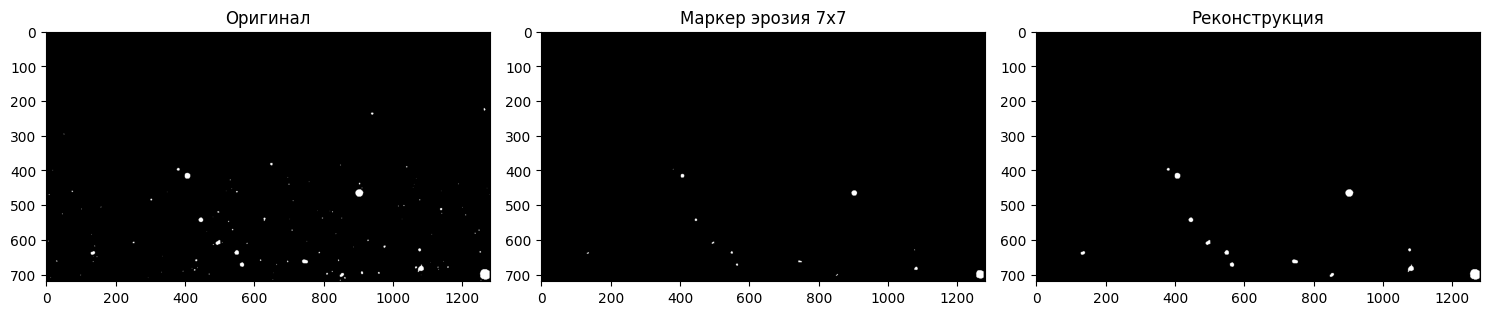

In [20]:
img_balls = cv2.imread("Шарики.png", cv2.IMREAD_GRAYSCALE)

# бинаризация
_, thresh_balls = cv2.threshold(img_balls, 127, 255, cv2.THRESH_BINARY)

# функ морфологической реконструкции
def morph_reconstruct(marker, mask): #маркер сжатая картинка без шума, маска оригинал с шумом
    # выбираем ядро 3х3 для дилатации
    kernel = np.ones((3, 3), np.uint8)
    while True:
        # расширяем маркер
        dilated = cv2.dilate(marker, kernel)
        # оставляем только то, что есть в маске
        reconstructed = cv2.bitwise_and(dilated, mask)
        if np.array_equal(reconstructed, marker):
            break # если картинка перестала меняться то останавливаемся
        marker = reconstructed # если картинка меняется обновляем маркер
    return marker

# ядро 7х7 убирает все что меньше 7 пикселей, подобрано опытным путем, итерация 1
kernel_erode_big = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
marker_big = cv2.erode(thresh_balls, kernel_erode_big, iterations=1)
reconstructed_big = morph_reconstruct(marker_big, thresh_balls)# вызов реконструкции

# отображение
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(thresh_balls, cmap='gray')
plt.title("Оригинал")

plt.subplot(1, 3, 2)
plt.imshow(marker_big, cmap='gray')
plt.title("Маркер эрозия 7х7")

plt.subplot(1, 3, 3)
plt.imshow(reconstructed_big, cmap='gray')
plt.title("Реконструкция")

plt.tight_layout()
plt.show()

In [22]:
# функция подсчета объектов с фильтрацией по площади
def count_objects(img_binary, min_area=10):
    # num_labels количество найденных объектов, stats таблица со статистикой по каждому объекту
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(img_binary, connectivity=8)
    # считаем объекты у которых площадь больше мин площади
    valid_count = 0
    for i in range(1, num_labels): # фон не считаем
        if stats[i, cv2.CC_STAT_AREA] >= min_area: # берет из таблицы stats площадь iго
            valid_count += 1

    return valid_count

# считаем объекты на оригинале
count_original = count_objects(thresh_balls)

# считаем объекты после реконструкции
count_reconstructed = count_objects(reconstructed_big)

print(f"Количество до реконструкции{count_original}")
print(f"Количество после реконструкции реконструкции: {count_reconstructed}")
print(f"Удалено объектов шума: {count_original - count_reconstructed}")

Количество до реконструкции42
Количество после реконструкции реконструкции: 13
Удалено объектов шума: 29


In [23]:
from google.colab import files
uploaded = files.upload()

Saving rice.jpg to rice.jpg


Найдено зерен риса: 93


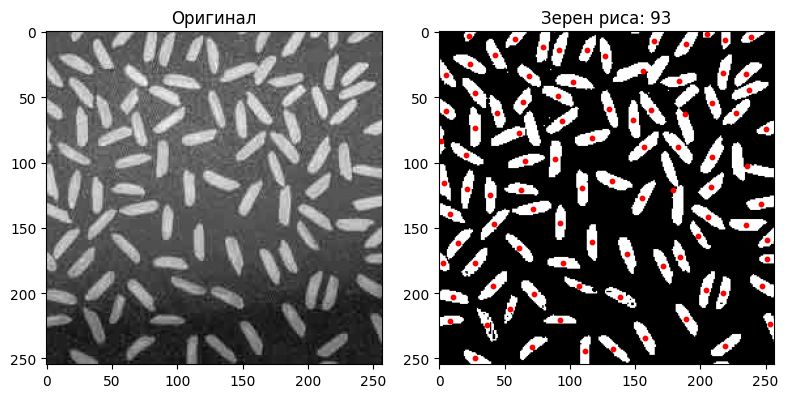

In [44]:
def morph_reconstruct(marker, mask):
    kernel = np.ones((3, 3), np.uint8)
    while True:
        # расширяем маркер но не ярче оригинала
        new = np.minimum(cv2.dilate(marker, kernel), mask)
        if np.array_equal(marker, new):
            return new
        marker = new

# загружаем в режиме чб
img = cv2.imread("rice.jpg", 0)

se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))

bg = morph_reconstruct(cv2.erode(img, se), img) #стираем зерна, восстанавливаем фон без зерен

# вычитаем фон из оригинала
grains = cv2.subtract(img, bg)

# переводим в чб через порог оцу
_, binary = cv2.threshold(grains, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# находим все белые пятна и их центры масс
_, _, stats, centroids = cv2.connectedComponentsWithStats(binary)

# оставляем зерна без фона и шума
valid = stats[1:, cv2.CC_STAT_AREA] >= 25
pts = centroids[1:][valid]
print(f"Найдено зерен риса: {len(pts)}")

# jnj,hf;tybt
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

# левый график,ориг
ax[0].imshow(img, cmap="gray")
ax[0].set_title("Оригинал")

# правый график с центрами масс
ax[1].imshow(binary, cmap="gray")
ax[1].scatter(pts[:, 0], pts[:, 1], c="red", s=10)
ax[1].set_title(f"Зерен риса: {len(pts)}")

plt.tight_layout()
plt.show()

In [ ]:
'''Получилось почти везде, проблемы остались только со слипшимися зернами'''